# H15 Part A · Step 7 · The side-car on nuScenes, as recorded and warped to NAVSIM's camera

Step 7 of [the plan](../../../docs/drivejepa-perception-sidecar-A.md) (§8.2, choice 11.12) reads the chosen
side-car (v3 for 24 epochs, seeds 0–2) and the no-camera control on H15's 100 nuScenes train scenes: 2,917
keyframes that neither the side-car nor the released model ever saw. It reads them twice:

1. **as recorded**: nuScenes' own camera, through the vendor's crop and resize. This read decides **Q9**;
2. **warped**: each frame turned and rescaled to NAVSIM's CAM_F0 by a homography, keeping nuScenes' camera
   centre. A diagnostic with no prediction: does the distance error follow the camera's geometry?

Nothing trains. Everything below is read from the run's files (`ood read-sidecar`, recipe stage
`part-a-7-read`; the warp from `ood warp-pass`, stage `part-a-7-warp-pass`), except §7's drawings, which run
seed 0's side-car again on a few keyframes.

**Kernel:** `drive-jepa-v2` ("Drive-JEPA v2"), which starts `[python] drivejepa` (Python 3.9, torch 2.1). Not
`python3`, which has no torch. Headless: `scripts/run_notebooks.py`.

In [1]:
import json
import os
import pickle
import sys
import warnings
from pathlib import Path

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "gallops").is_dir())
sys.path.insert(0, str(REPO / "src"))
os.environ.setdefault("GALLOPS_CONFIG", str(REPO / "gallops.toml"))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Polygon
from matplotlib.ticker import FuncFormatter

from gallops.config import SiteConfig
from gallops.drivejepa_perception import evaluate, navsim_data, ood, train_sidecar, views
from gallops.drivejepa_perception import targets as tg

views.use_style()
pd.set_option("display.precision", 3)
cfg = SiteConfig.load()
RUNS = Path(cfg.resolve("{runs}")) / "drivejepa_perception"
NUSC = Path(cfg.resolve("{data.nuscenes}"))
readout = json.loads((RUNS / "part-a" / "7-nuscenes" / "readout.json").read_text())
details = np.load(RUNS / "part-a" / "7-nuscenes" / "details.npz")
warp = json.loads((RUNS / "nusc-warp-v1" / "manifest.json").read_text())
with open(RUNS / "nusc-extract" / "extract.pkl", "rb") as fh:
    extract = pickle.load(fh)
scenes = extract["scenes"]
ticks = ood.ood_ticks(extract)
labels = dict(np.load(RUNS / "nusc-v1" / "labels.npz"))
outputs = np.load(RUNS / "nusc-v1" / "outputs.npz")
proj = {
    "recorded": (tg.to_512(*ood.NUSC_SIZE) @ outputs["lidar2img"][:, tg.FRONT_SLOT].astype(np.float64)).astype(np.float32),
    "warped": np.load(RUNS / "nusc-warp-v1" / "projection.npy"),
}
SEEDS = ["5b-v3-e24-s0", "5b-v3-e24-s1", "5b-v3-e24-s2"]
BLIND = "5b-v3-e24-blind-s0"
NAMES = {**{s: f"seed {s[-1]}" for s in SEEDS}, BLIND: "no camera"}
print(f"{readout['rows']:,} keyframes in both reads, {readout['scenes']} scenes; read at {readout['gallops_sha'][:7]}")


def y_axis_left(ax):
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{-v:g}"))
    ax.set_xlabel("y (m): + left, − right")
    ax.set_ylabel("x (m), forward")

2,917 keyframes in both reads, 100 scenes; read at 19456b5


## 1. What was read, and the checks it passed first

The readout refuses to read nuScenes unless each run, read by its own code on NAVSIM's select logs, gives
the select F1 its training recorded (check a). The warp pass refuses to write unless the homography and
the warped camera agree on every scene (check c) and the identity warp reproduces the as-recorded ViT
output (check b).

In [2]:
check_a = pd.DataFrame(readout["check_a_select_f1"]).T.rename(index=NAMES)
check_a = check_a[["kept_epoch", "recorded_f1", "reread_f1", "gap"]]
display(check_a.rename(columns={"recorded_f1": "select F1, recorded", "reread_f1": "select F1, this code"}))
print(f"check b, identity warp against nusc-v1's ViT output on {warp['identity_parity']['rows']} rows: "
      f"largest difference {warp['identity_parity']['max_abs']}")
print(f"check c, homography against the warped camera: largest gap {warp['warp_gap_px_max']:.1e} px over all scenes")

,kept_epoch,"select F1, recorded","select F1, this code",gap
seed 0,24.0,0.719,0.719,0.0
seed 1,21.0,0.718,0.718,0.0
seed 2,24.0,0.713,0.713,0.0
no camera,23.0,0.041,0.041,0.0


check b, identity warp against nusc-v1's ViT output on 32 rows: largest difference 0.0
check c, homography against the warped camera: largest gap 2.7e-12 px over all scenes


## 2. The camera it warps to, and what the warp does

**The target camera, by a fixed rule:** of navtrain's train rows, the one whose CAM_F0 lands a grid of points
ahead closest to the per-point median (NAVSIM's camera varies by half a degree, plan §4.1). Its intrinsics come
out as NAVSIM's own: focal 1545 px, principal point (960, 560) on 1920 × 1080.

**Each scene's warp** swaps nuScenes' intrinsics and its camera's rotation on the ego frame for that camera's,
about nuScenes' own camera centre: exact for every scene point. Then the vendor's crop and resize, as on
NAVSIM.

In [3]:
target = warp["target_camera"]
print(f"target camera: navtrain row {target['row']}, token {target['token']}, log {target['log']}; "
      f"{target['cost_px']:.2f} px from the median")
k = np.asarray(target["k"])
print(f"K: focal {k[0, 0]:.1f} / {k[1, 1]:.1f} px, principal point ({k[0, 2]:.1f}, {k[1, 2]:.1f})")
per_scene = pd.DataFrame(warp["scenes"]).T
per_scene["location"] = [scenes[s]["location"] for s in per_scene.index]
display(per_scene.groupby("location")[["turn_deg", "black_share"]].agg(["min", "median", "max"]))

target camera: navtrain row 77655, token 16542f9377865ada, log 2021.08.31.11.47.30_veh-40_00248_00376; 0.97 px from the median
K: focal 1545.0 / 1545.0 px, principal point (960.0, 560.0)


turn_deg               black_share              
                              min median    max         min median    max
location                                                                 
boston-seaport              2.409  2.409  2.409       0.035  0.035  0.035
singapore-hollandvillage    1.314  1.314  1.314       0.036  0.036  0.036
singapore-onenorth          1.314  1.314  1.314       0.036  0.036  0.036
singapore-queenstown        1.314  1.314  1.314       0.036  0.036  0.036

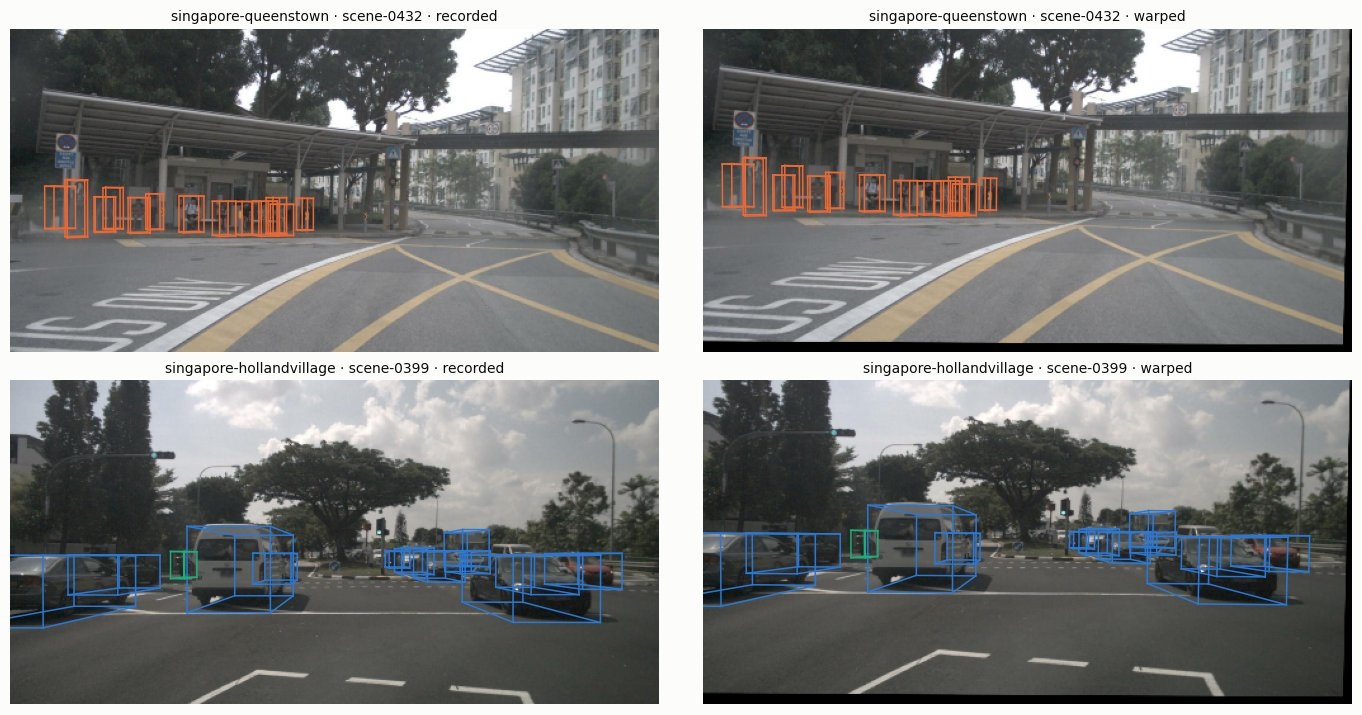

In [4]:
def warped_image(row):
    """The keyframe's current frame as the warp pass made it: nuScenes' frame turned to the target camera."""
    import cv2

    tick = ticks[row]
    frame = scenes[tick["scene"]]["keyframes"][tick["keyframe"]]
    cam = scenes[tick["scene"]]["calibration"]["CAM_FRONT"]
    pose = np.asarray(cam["pose"], dtype=np.float64)
    h = ood.homography(np.asarray(cam["intrinsics"], dtype=np.float64), pose[:3, :3].T, k, np.asarray(target["rotation"]))
    image = views.read_image(NUSC / frame["file"])
    return image, cv2.warpPerspective(image, h, ood.NAVSIM_SIZE, flags=cv2.INTER_LINEAR, borderValue=0)


def targets_of(row, variant):
    return tg.build(navsim_data.agents_of(labels, row), proj[variant][row])


rows_all = details["rows"]
rng = np.random.default_rng(7)
picked = []
for r in rng.permutation(rows_all):
    if targets_of(r, "recorded")["mask"].sum() >= 4 and scenes[ticks[r]["scene"]]["location"] not in [
        scenes[ticks[p]["scene"]]["location"] for p in picked
    ]:
        picked.append(int(r))
    if len(picked) == 2:
        break

fig, axes = plt.subplots(2, 2, figsize=(14, 7.2))
for i, r in enumerate(picked):
    image, warped = warped_image(r)
    for ax, (variant, view) in zip(axes[i], (("recorded", image), ("warped", warped))):
        t = targets_of(r, variant)
        ax.imshow(views.model_view(view))
        for q in np.flatnonzero(t["mask"]):
            for (u0, v0), (u1, v1) in views.box_edges_2d(proj[variant][r].astype(np.float64), t["box"][q][None])[0]:
                ax.plot([u0, u1], [v0, v1], color=views.CLASS_COLOURS[t["cls"][q]], lw=1.1)
        ax.set_xlim(0, 512)
        ax.set_ylim(256, 0)
        ax.axis("off")
        ax.set_title(f"{scenes[ticks[r]['scene']]['location']} · {ticks[r]['scene']} · {variant}")
plt.tight_layout()
views.show_jpeg(fig)

**Reading it:** the warped frame is the same image turned by about 2° and scaled by about 2%. The labels drawn
through each read's own projection sit on the agents in both. The black band is where NAVSIM's camera would see
below nuScenes' frame: 3.5% of the rows the ViT reads, at the bottom, where near vehicles meet the road.

## 3. Q9: vehicles within 30 m, as recorded

**Q9 (PREDICTIONS.md, committed at step 4):** vehicle recall at 2 m within 30 m. Predicted 0.40–0.55; supports
if ≥ 0.30, refutes if < 0.20. Read on every seed at its kept epoch, with 95% intervals from 1,000 draws of
whole scenes (a scene's keyframes are 0.5 s apart). The last epoch, which nothing chose, beside it.

In [5]:
def q9_table(variant):
    out = {}
    for run in SEEDS + [BLIND]:
        for which in ("kept", "last"):
            x = readout["variants"][variant][run][which]
            q = x["q9_vehicles_within_30m"]
            out[(NAMES[run], which)] = {
                "epoch": x["epoch"],
                "vehicle recall": q["recall"],
                "95% interval": f"{q['recall_95'][0]:.3f}–{q['recall_95'][1]:.3f}",
                "vehicle precision": q["precision"],
                "vehicles within 30 m": q["targets"],
            }
    return pd.DataFrame(out).T


display(q9_table("recorded"))
q9 = [readout["variants"]["recorded"][s]["kept"]["q9_vehicles_within_30m"]["recall"] for s in SEEDS]
verdict = "supported" if min(q9) >= 0.30 else ("refuted" if min(q9) < 0.20 else "neither")
print(f"Q9: {', '.join(f'{v:.3f}' for v in q9)} at the kept epochs; mean {np.mean(q9):.3f}. Rule: {verdict} on every seed.")
print("First pass, for reference (v1, seed 0, the first pass's own scenes): 0.480.")

epoch vehicle recall 95% interval vehicle precision  \
seed 0    kept    24          0.526  0.481–0.570             0.621   
          last    24          0.526  0.481–0.570             0.621   
seed 1    kept    21          0.532  0.485–0.578             0.631   
          last    24          0.515  0.469–0.563             0.621   
seed 2    kept    24          0.537  0.495–0.583             0.647   
          last    24          0.537  0.495–0.583             0.647   
no camera kept    23           0.12  0.097–0.145             0.024   
          last    24          0.094  0.069–0.120             0.029   

               vehicles within 30 m  
seed 0    kept                 3575  
          last                 3575  
seed 1    kept                 3575  
          last                 3575  
seed 2    kept                 3575  
          last                 3575  
no camera kept                 3575  
          last                 3575

Q9: 0.526, 0.532, 0.537 at the kept epochs; mean 0.532. Rule: supported on every seed.
First pass, for reference (v1, seed 0, the first pass's own scenes): 0.480.


## 4. Every measure, as recorded and warped

The mean of the three seeds at their kept epochs, and their range. NAVSIM's select logs (step 5, the same
runs, in domain) for comparison where step 5 read the same measure.

In [6]:
MEASURES = [
    ("recall within 30 m", lambda x: x["all_classes_within_30m"]["recall"]),
    ("precision within 30 m", lambda x: x["all_classes_within_30m"]["precision"]),
    ("F1 within 30 m", lambda x: x["all_classes_within_30m"]["f1"]),
    ("vehicles, recall within 30 m (Q9)", lambda x: x["recall_2m_within_30m_by_class"][0]),
    ("pedestrians, recall within 30 m", lambda x: x["recall_2m_within_30m_by_class"][1]),
    ("cyclists, recall within 30 m", lambda x: x["recall_2m_within_30m_by_class"][2]),
    ("recall 0–20 m", lambda x: x["recall_by_range"][0]),
    ("recall 20–30 m", lambda x: x["recall_by_range"][1]),
    ("recall 30–50 m", lambda x: x["recall_by_range"][2]),
    ("AP at 2 m within 30 m, vehicles", lambda x: x["ap_2m_within_30m"]["vehicle"]),
    ("AP at 2 m within 30 m, pedestrians", lambda x: x["ap_2m_within_30m"]["pedestrian"]),
    ("causal recall (chosen rule), to 50 m", lambda x: x["recall_causal_chosen"]),
    ("causal recall (strict rule), to 50 m", lambda x: x["recall_causal_strict"]),
    ("hidden agents, recall", lambda x: x["recall_hidden"]),
    ("nearest target, recall", lambda x: x["recall_nearest_1"]),
    ("moving vehicles within 20 m, recall", lambda x: x["moving_vehicles_20m_recall"]),
    ("centre error of hits (m)", lambda x: x["centre_error_m"]),
    ("velocity error of hits (m/s)", lambda x: x["velocity_error_mps"]),
    ("1 s path FDE, moving (m)", lambda x: x["path_fde_1s_model_moving"]),
    ("1 s path FDE, constant velocity (m)", lambda x: x["path_fde_1s_cv_pred_moving"]),
    ("lead-vehicle gap error (m)", lambda x: x["lead_gap_mae_m"]),
    ("lead gap, the prior's error (m)", lambda x: x["lead_gap_prior_mae_m"]),
    ("detections a keyframe", lambda x: x["detections_per_sample"]),
]
rows_ = {}
for name, get in MEASURES:
    entry = {}
    for variant in ("recorded", "warped"):
        values = [get(readout["variants"][variant][s]["kept"]) for s in SEEDS]
        entry[f"{variant}, mean"] = np.mean(values)
        entry[f"{variant}, seeds"] = f"{min(values):.3f}–{max(values):.3f}"
    entry["no camera, recorded"] = get(readout["variants"]["recorded"][BLIND]["kept"])
    rows_[name] = entry
table = pd.DataFrame(rows_).T
table["warped − recorded"] = table["warped, mean"] - table["recorded, mean"]
display(table)

,"recorded, mean","recorded, seeds","warped, mean","warped, seeds","no camera, recorded",warped − recorded
recall within 30 m,0.41,0.407–0.415,0.341,0.328–0.349,0.081,-0.069
precision within 30 m,0.625,0.616–0.642,0.56,0.543–0.581,0.024,-0.065
F1 within 30 m,0.495,0.491–0.504,0.424,0.409–0.436,0.037,-0.071
"vehicles, recall within 30 m (Q9)",0.532,0.526–0.537,0.438,0.424–0.446,0.12,-0.094
"pedestrians, recall within 30 m",0.155,0.154–0.159,0.133,0.128–0.143,0.0,-0.022
"cyclists, recall within 30 m",0.143,0.051–0.212,0.124,0.053–0.172,0.0,-0.02
recall 0–20 m,0.574,0.566–0.587,0.488,0.461–0.507,0.116,-0.085
recall 20–30 m,0.304,0.304–0.305,0.246,0.241–0.254,0.058,-0.058
recall 30–50 m,0.103,0.100–0.105,0.116,0.114–0.119,0.028,0.014
"AP at 2 m within 30 m, vehicles",0.541,0.534–0.556,0.398,0.367–0.417,0.008,-0.143


**In domain, for comparison** (step 5, NAVSIM's select logs, the same three runs; the executive update and
plan §9.2): F1 within 30 m 0.713–0.719; causal recall 0.90; moving vehicles within 20 m 0.95–0.96; AP 0.87 for
vehicles and 0.54 for pedestrians; depth error 0.24 m within 10 m; direction under 1°. NAVSIM's labels are
auto-labels with no visibility filter; nuScenes' are human labels, kept only with at least one lidar point
(plan §8.2), so nuScenes' targets are more visible.

## 5. Distance against direction: does the error follow the camera's geometry?

Each target paired with a detection of its class within 5 m; its position error split along the camera's ray
(depth: positive means placed too far) and across it (direction, as an angle seen from the camera). Seed 0,
kept epoch; the other seeds read alike.

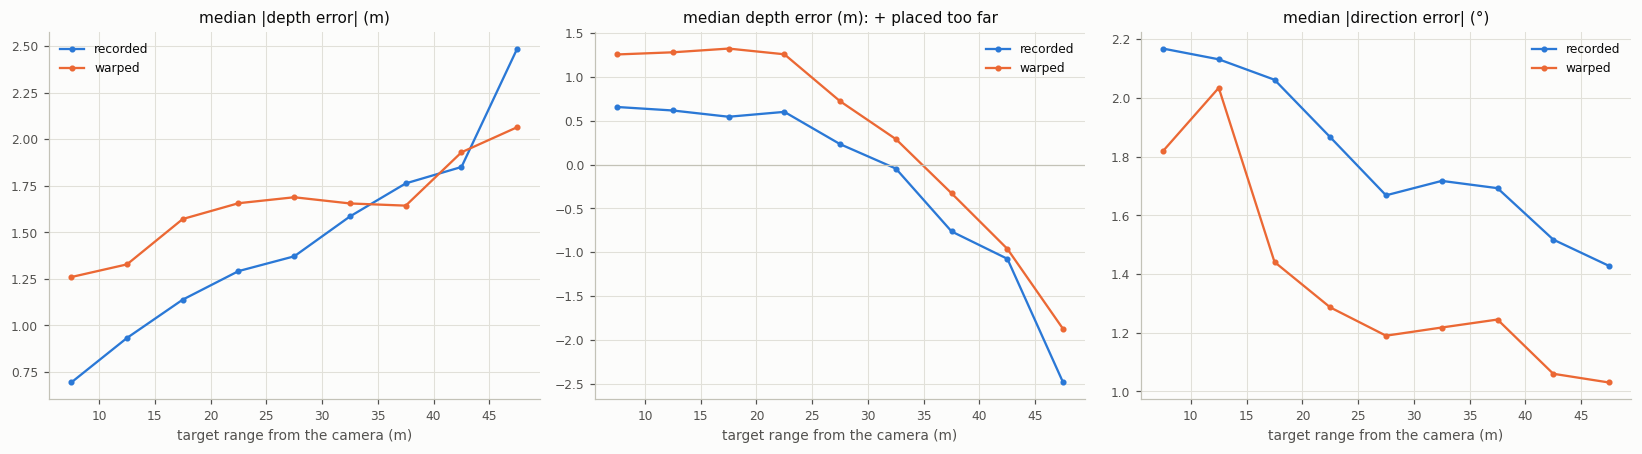

,recorded,warped
0–10 m,|depth| 0.69 · depth +0.66 · |dir| 2.27° · >2 ...,|depth| 1.26 · depth +1.25 · |dir| 1.87° · >2 ...
10–20 m,|depth| 1.02 · depth +0.58 · |dir| 2.08° · >2 ...,|depth| 1.43 · depth +1.30 · |dir| 1.66° · >2 ...
20–30 m,|depth| 1.33 · depth +0.45 · |dir| 1.76° · >2 ...,|depth| 1.66 · depth +1.02 · |dir| 1.22° · >2 ...
30–50 m,|depth| 1.73 · depth -0.52 · |dir| 1.67° · >2 ...,|depth| 1.77 · depth -0.19 · |dir| 1.19° · >2 ...


In [7]:
bins = np.arange(0, 55, 5.0)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for variant, colour in (("recorded", views.CLASS_COLOURS[0]), ("warped", views.CLASS_COLOURS[1])):
    key = f"{variant}_{SEEDS[0]}_kept_ray"
    reach, depth, direction = details[f"{key}_range"], details[f"{key}_depth"], details[f"{key}_direction_deg"]
    centres = bins[:-1] + 2.5
    which = np.digitize(reach, bins) - 1
    med_abs = [np.median(np.abs(depth[which == b])) if (which == b).sum() > 20 else np.nan for b in range(len(centres))]
    med = [np.median(depth[which == b]) if (which == b).sum() > 20 else np.nan for b in range(len(centres))]
    med_dir = [np.median(np.abs(direction[which == b])) if (which == b).sum() > 20 else np.nan for b in range(len(centres))]
    axes[0].plot(centres, med_abs, marker="o", ms=3, color=colour, label=variant)
    axes[1].plot(centres, med, marker="o", ms=3, color=colour, label=variant)
    axes[2].plot(centres, med_dir, marker="o", ms=3, color=colour, label=variant)
axes[1].axhline(0, color=views.AXIS, lw=0.8)
for ax, title in zip(axes, ("median |depth error| (m)", "median depth error (m): + placed too far", "median |direction error| (°)")):
    ax.set_xlabel("target range from the camera (m)")
    ax.set_title(title)
    ax.legend()
plt.tight_layout()
plt.show()
pd.DataFrame(
    {
        variant: {
            f"{b['range_m'][0]:g}–{b['range_m'][1]:g} m": f"|depth| {b['median_abs_depth_m']:.2f} · depth {b['median_depth_m']:+.2f} · |dir| {b['median_abs_direction_deg']:.2f}° · >2 m {b['share_depth_over_2m']:.0%}"
            for b in readout["variants"][variant][SEEDS[0]]["kept"]["ray_errors"]
        }
        for variant in ("recorded", "warped")
    }
)

**Reading it** (*measured*, all three seeds alike):
- **As recorded, distance is again the weak part,** and more so than on NAVSIM: 0.6–0.7 m within 10 m (NAVSIM
  0.24 m), 1.7 m at 30–50 m. Agents within 30 m are placed too far by a median 0.5–0.7 m; beyond 30 m, too near.
  Direction is off by 1.6–2.3° (NAVSIM: under 1°).
- **The warp straightens direction but not distance.** Direction improves at every range (to 1.2° beyond 20 m):
  the turn the warp applies is the one the cameras differ by. Distance gets worse: within 20 m, agents are now
  placed a median 1.0–1.4 m too far, and recall falls by 8–11 points within 30 m.
- **So this read does not show that the camera's geometry is the gap** (*argued*). The warp aligns each camera's
  rotation on its own ego frame. The side-car judges distance from where an agent meets the road in the image,
  which depends on the camera's pitch against the road; if the two datasets' ego frames sit differently on the
  road, an exact ego-frame warp can tilt the view by about a degree, which at 10 m moves a placement by about half
  a metre, the size of the change here. The warp also adds a black band at the bottom (3.5% of the rows the ViT
  reads, where near agents meet the road) and a second resampling. This read cannot tell these apart; a warp of
  the yaw alone, or one fitted to the ground, would.

## 6. By location, traffic side, night and rain (as recorded)

Vehicles and all classes within 30 m, seed 0 at its kept epoch, with intervals over that group's scenes. In this
draw, all 11 night scenes are in Singapore and all 21 rain scenes in Boston (plan §8.2): night and rain cannot be
told apart from place here.

In [8]:
groups = readout["variants"]["recorded"][SEEDS[0]]["kept"]["by_group"]
display(
    pd.DataFrame(
        {
            g: {
                "keyframes": d["keyframes"],
                "scenes": d["scenes"],
                "vehicle recall": d["vehicles"]["recall"],
                "vehicle 95%": f"{d['vehicles']['recall_95'][0]:.2f}–{d['vehicles']['recall_95'][1]:.2f}",
                "all classes F1": d["all_classes"]["f1"],
                "all classes recall": d["all_classes"]["recall"],
                "targets within 30 m": d["all_classes"]["targets"],
            }
            for g, d in groups.items()
        }
    ).T
)

,keyframes,scenes,vehicle recall,vehicle 95%,all classes F1,all classes recall,targets within 30 m
location=boston-seaport,1880,64,0.522,0.47–0.58,0.507,0.429,3593
location=singapore-hollandvillage,307,10,0.58,0.47–0.66,0.507,0.469,429
location=singapore-onenorth,468,17,0.548,0.44–0.69,0.485,0.388,935
location=singapore-queenstown,262,9,0.355,0.06–0.50,0.236,0.149,323
traffic=left,1037,36,0.539,0.46–0.61,0.454,0.363,1687
traffic=right,1880,64,0.522,0.47–0.58,0.507,0.429,3593
night,331,11,0.543,0.26–0.65,0.395,0.333,403
rain,623,21,0.539,0.45–0.62,0.51,0.441,1035


**Reading it:** left-hand traffic costs vehicles nothing (0.54 against 0.52, Singapore against Boston), so
choice 11.10's measurement finds no reason for a traffic-side input; all classes are lower in Singapore (0.45 F1
against 0.51), mostly pedestrians. Queenstown is the weakest place and the least certain (9 scenes).

## 7. Confidence, and the detections drawn

**Calibration** (seed 0, kept, as recorded): how often a slot of a given confidence is right.

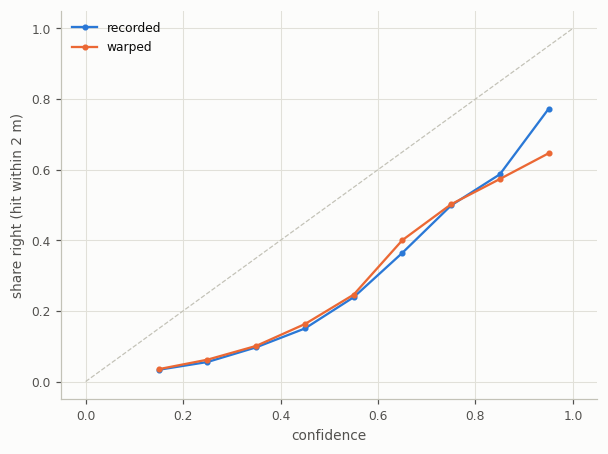

In [9]:
fig, ax = plt.subplots(figsize=(5.6, 4.2))
for variant, colour in (("recorded", views.CLASS_COLOURS[0]), ("warped", views.CLASS_COLOURS[1])):
    cal = readout["variants"][variant][SEEDS[0]]["kept"]["calibration"]
    ax.plot(cal["centre"], cal["right"], marker="o", ms=3, color=colour, label=variant)
ax.plot([0, 1], [0, 1], color=views.AXIS, lw=0.8, ls="--")
ax.set_xlabel("confidence")
ax.set_ylabel("share right (hit within 2 m)")
ax.legend()
plt.tight_layout()
plt.show()

**Detections** of seed 0 at its kept epoch on two keyframes, as recorded and warped. Coloured boxes are the
labels, white boxes the detections; from above, green dots are detections that hit a target and red ones false
alarms.

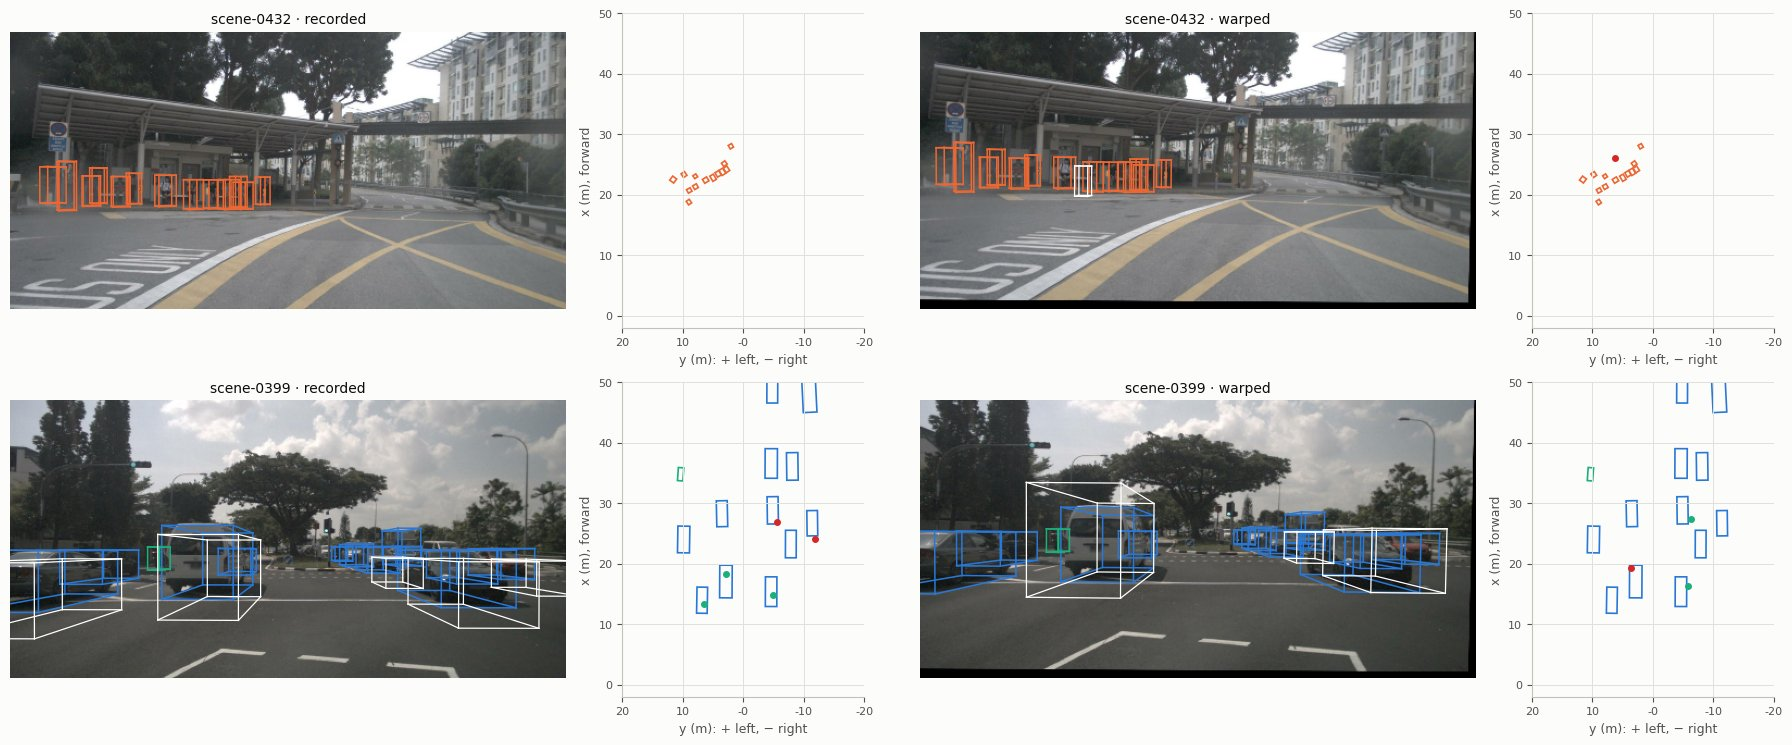

In [10]:
import torch

model, kept = train_sidecar.load_run(RUNS / "part-a" / SEEDS[0])
model = model.float().eval()
vit = {"recorded": np.load(RUNS / "nusc-v1" / "vit_out.npy", mmap_mode="r"), "warped": np.load(RUNS / "nusc-warp-v1" / "vit_out.npy", mmap_mode="r")}


def detections(row, variant):
    with torch.no_grad():
        tok = torch.from_numpy(np.asarray(vit[variant][row], dtype=np.float32))[None]
        out = model(tok, torch.from_numpy(proj[variant][row])[None])[-1]
    pred = evaluate.decode({key: v[0].numpy() for key, v in out.items()})
    pred["box"] = out["box"][0].numpy()
    return pred


fig, axes = plt.subplots(2, 4, figsize=(18, 7.6), gridspec_kw={"width_ratios": [2.3, 1, 2.3, 1]})
for i, r in enumerate(picked):
    image, warped = warped_image(r)
    for j, (variant, view) in enumerate((("recorded", image), ("warped", warped))):
        t = targets_of(r, variant)
        pred = detections(r, variant)
        shown = np.flatnonzero(pred["conf"] >= evaluate.THR)
        ax = axes[i, 2 * j]
        ax.imshow(views.model_view(view))
        p64 = proj[variant][r].astype(np.float64)
        for q in np.flatnonzero(t["mask"]):
            for (u0, v0), (u1, v1) in views.box_edges_2d(p64, t["box"][q][None])[0]:
                ax.plot([u0, u1], [v0, v1], color=views.CLASS_COLOURS[t["cls"][q]], lw=1.1)
        for q in shown:
            box = np.r_[pred["xyz"][q], np.exp(pred["box"][q, 3:6]), np.arctan2(pred["box"][q, 6], pred["box"][q, 7])]
            for (u0, v0), (u1, v1) in views.box_edges_2d(p64, box[None])[0]:
                ax.plot([u0, u1], [v0, v1], color="white", lw=0.9)
        ax.set_xlim(0, 512)
        ax.set_ylim(256, 0)
        ax.axis("off")
        ax.set_title(f"{ticks[r]['scene']} · {variant}")
        bev = axes[i, 2 * j + 1]
        m = t["mask"]
        _, tp, _ = evaluate.match(pred["conf"], pred["cls"], pred["xyz"][:, :2], t["box"][m, :2].astype(np.float64), t["cls"][m])
        for q in np.flatnonzero(m):
            outline = views.footprint(t["box"][q][None])[0]
            bev.add_patch(Polygon(np.c_[-outline[:, 1], outline[:, 0]], closed=True, fill=False, ec=views.CLASS_COLOURS[t["cls"][q]], lw=1.2))
        order = shown[np.argsort(-pred["conf"][shown], kind="stable")]
        for q, ok in zip(order, tp):
            bev.plot(-pred["xyz"][q, 1], pred["xyz"][q, 0], "o", ms=4, color="#1baf7a" if ok else "#d62728")
        bev.set_xlim(-20, 20)
        bev.set_ylim(-2, 50)
        bev.set_aspect("equal")
        y_axis_left(bev)
plt.tight_layout()
views.show_jpeg(fig)

## 8. Summary for the review

**Q9 is supported on every seed.** As recorded, the side-car finds 0.526, 0.532 and 0.537 of the vehicles within
30 m (intervals over scenes about ±0.045), inside the predicted 0.40–0.55 and above the 0.30 bar. The first
pass's smaller v1 found 0.480 on its own draw. The no-camera control finds 0.12 by its priors alone, at a
precision of 0.02.

**Out of domain it is a weaker detector, in the same ways** (*measured*): F1 within 30 m 0.49–0.50 against
0.713–0.719 on NAVSIM; pedestrians fall furthest (0.15–0.16 within 30 m); causal recall 0.65–0.67 (NAVSIM 0.90);
distance error two to three times NAVSIM's near the car; direction 1.6–2.3°.

**The warp to NAVSIM's camera does not help:** direction improves, distance gets worse, recall falls 8–11 points.
Whether the camera's geometry is the gap stays open (§5): the warp changes the view's tilt against the road, adds
a black band and resamples, and this read cannot separate them.

**What it means for Phase B** (*argued*): on nuScenes the planner would get noticeably weaker agents than on
NAVSIM, especially pedestrians and depth near the car. Any B idea read on nuScenes (the B plan, §8.4) reads it
with that input.